# Bantay-Baha: raw data check and quick EDA

One pass over every dataset in the concept proposal (Appendix B, Table 1): does it exist, does it download, does it cover
what the proposal assumes? Data come from `python scripts/download_data.py` (open sources) and
`python scripts/download_gee.py --project <id>` (Earth Engine sources). Sections whose files are missing print `PENDING` and skip.

| # | Layer | Dataset | Folder |
|---|---|---|---|
| 1 | Target | DOH-Epi dengue, province/city x week, 2016 to Jan 2021 (HDX) | `dengue_hdx` |
| 2 | Target (lepto) | Project CCHAIN PIDSR city-week disease totals, 2008-2022 | `cchain` |
| 3 | Cross-check | Mendeley Parreño 2023 national weekly notifiable diseases, 2019-2023 | `mendeley_parreno` |
| 4 | Cross-check | OpenDengue V1.3 | `opendengue` |
| 5 | Join keys | HDX COD-AB boundaries; 2020 CPH population | `cod_ab`, `census2020` |
| 6 | Storms | IBTrACS v04r01 WP | `ibtracs` |
| 7 | Rain | CHIRPS v2.0 daily 0.05 deg; GPM IMERG V07 (GEE) | `chirps`, `imerg` |
| 8 | Flood | Copernicus EMS EMSR312/EMSR478; UP NOAH 5/25-yr hazard; GFD + Sentinel-1 inventory (GEE) | `copernicus_ems`, `noah`, `gfd`, `sentinel1` |
| 9 | Rivers | HydroRIVERS v1.0 Australasia | `hydrorivers` |
| 10 | Access | OSM (Geofabrik), roroph RoRo routes, HOT OSM + NOAH health facilities, MAP friction 2019 (GEE) | `osm`, `roroph`, `hotosm_health`, `noah_facilities`, `map_friction` |
| 11 | Population | WorldPop 2020 100 m; Meta HRSL under-5 / 60+ | `worldpop`, `meta_hrsl` |

In [1]:
import re, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .3})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
BBOX = (116, 4, 127, 21.5)
FINDINGS = []  # (dataset, finding) collected for the summary at the end
def note(ds, msg): FINDINGS.append((ds, msg)); print(f"[{ds}] {msg}")
def have(*parts):
    p = RAW.joinpath(*parts)
    ok = p.exists() and (p.is_file() or any(p.iterdir()))
    if not ok: print(f"PENDING: {p.relative_to(ROOT)} not downloaded")
    return ok

if (RAW / "MANIFEST.csv").exists():
    man = pd.read_csv(RAW / "MANIFEST.csv")
else:  # fall back to what is on disk
    fs = [p for p in RAW.rglob("*") if p.is_file() and p.suffix != ".part" and p.name != "MANIFEST.csv"]
    man = pd.DataFrame({"source": [p.relative_to(RAW).parts[0] for p in fs], "path": fs, "bytes": [p.stat().st_size for p in fs]})
man.groupby("source").agg(files=("path", "size"), MB=("bytes", lambda b: round(b.sum() / 1e6, 1))).sort_values("MB", ascending=False)

,files,MB
source,,
noah,142,4733.0
osm,1,611.0
chirps,5,562.7
cod_ab,2,369.8
worldpop,1,158.9
hydrorivers,2,139.3
ibtracs,1,114.6
meta_hrsl,2,111.9
opendengue,3,109.9


## 1. DOH-Epi dengue (HDX), the forecast target

In [2]:
dg = pd.read_csv(RAW / "dengue_hdx/doh-epi-dengue-data-2016-2021.csv", skiprows=[1])  # row 1 = HXL tags
dg["loc"] = dg["loc"].str.strip(); dg["date"] = pd.to_datetime(dg["date"])
print(dg.shape, "| weeks:", dg.date.nunique(), dg.date.min().date(), "->", dg.date.max().date(), "| weekday:", dg.date.dt.day_name().unique().tolist())
print("locations:", dg["loc"].nunique(), "| regions:", dg.Region.nunique())
cities = sorted(l for l in dg["loc"].unique() if "CITY" in l or l in ("PATEROS", "TACLOBAN"))
print(f"{len(cities)} city-level units:", cities)
yr = dg.groupby(dg.date.dt.year).agg(rows=("cases", "size"), cases=("cases", "sum"), deaths=("deaths", "sum"), units=("loc", "nunique"))
yr["CFR_%"] = (yr.deaths / yr.cases * 100).round(2); yr

(32701, 5) | weeks: 261 2016-01-10 -> 2021-01-10 | weekday: ['Sunday']
locations: 126 | regions: 17
45 city-level units: ['ANGELES CITY', 'BACOLOD CITY', 'BAGUIO CITY', 'BASILIG CITY', 'BAYUGAN CITY', 'BUTUAN CITY', 'CABADBARAN CITY', 'CAGAYAN DE ORO CITY', 'CALOOCAN CITY', 'CEBU CITY', 'COTABATO CITY', 'DAGUPAN CITY', 'DAVAO CITY', 'GENERAL SANTOS CITY', 'ILIGAN CITY', 'ILOILO CITY', 'ISABELA CITY', 'LAPU-LAPU CITY', 'LAS PINAS CITY', 'LUCENA CITY', 'MAKATI CITY', 'MALABON CITY', 'MANDALUYONG CITY', 'MANDAUE CITY', 'MANILA CITY', 'MARIKINA CITY', 'MUNTINLUPA CITY', 'NAGA CITY', 'NAVOTAS CITY', 'OLONGAPO CITY', 'ORMOC CITY', 'PARANAQUE CITY', 'PASAY CITY', 'PASIG CITY', 'PATEROS', 'PUERTO PRINCESA CITY', 'QUEZON CITY', 'SAN JUAN CITY', 'SANTIAGO CITY', 'SURIGAO CITY', 'TACLOBAN', 'TAGUIG CITY', 'TANDAG CITY', 'VALENZUELA CITY', 'ZAMBOANGA CITY']


,rows,cases,deaths,units,CFR_%
date,,,,,
2016,6329,209544,8127.0,125,3.88
2017,6636,154155,4563.0,126,2.96
2018,6552,250783,1226.0,126,0.49
2019,6426,441902,1733.0,126,0.39
2020,6506,91041,1195.0,126,1.31
2021,252,2087,8.0,126,0.38


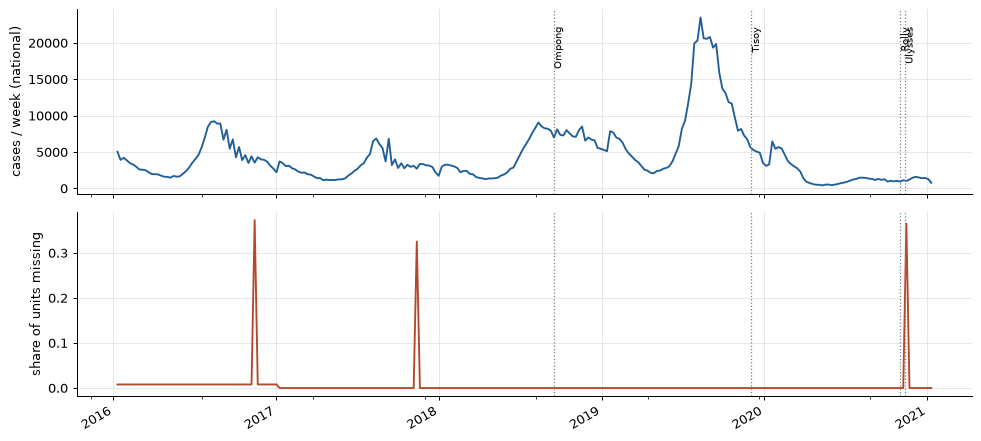

duplicate loc-week rows: 0 | negative cases: 0 | units with 0 cases all period: 0
[dengue_hdx] 126 reporting units (provinces + 45 HUC/NCR cities), not 81 provinces; HUCs must be folded into their geographic province (or kept as separate nodes).
[dengue_hdx] 2016 deaths = 8127 (CFR 3.88%), implausibly high vs other years; treat deaths as unreliable.
[dengue_hdx] 2020 cases = 91,041 vs 2019 441,902 (COVID reporting collapse), consistent with proposal using 2020 for access only. Data end 2021-01-10.


In [3]:
full = pd.MultiIndex.from_product([dg["loc"].unique(), np.sort(dg.date.unique())])
miss = 1 - dg.set_index(["loc", "date"]).reindex(full).cases.notna().groupby(level=1).mean()
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
dg.groupby("date").cases.sum().plot(ax=ax[0], color="#1f5f99"); ax[0].set_ylabel("cases / week (national)")
miss.plot(ax=ax[1], color="#b5482b"); ax[1].set_ylabel("share of units missing")
for d, n in [("2018-09-15", "Ompong"), ("2019-12-02", "Tisoy"), ("2020-11-01", "Rolly"), ("2020-11-11", "Ulysses")]:
    for a in ax: a.axvline(pd.Timestamp(d), color="grey", ls=":", lw=1)
    ax[0].text(pd.Timestamp(d), ax[0].get_ylim()[1] * .9, n, rotation=90, fontsize=8, va="top")
plt.tight_layout(); plt.show()
print("duplicate loc-week rows:", dg.duplicated(["loc", "date"]).sum(), "| negative cases:", (dg.cases < 0).sum(), "| units with 0 cases all period:", (dg.groupby("loc").cases.sum() == 0).sum())
note("dengue_hdx", f"{dg['loc'].nunique()} reporting units (provinces + {len(cities)} HUC/NCR cities), not 81 provinces; HUCs must be folded into their geographic province (or kept as separate nodes).")
note("dengue_hdx", f"2016 deaths = {yr.loc[2016,'deaths']:.0f} (CFR {yr.loc[2016,'CFR_%']}%), implausibly high vs other years; treat deaths as unreliable.")
note("dengue_hdx", f"2020 cases = {yr.loc[2020,'cases']:,} vs 2019 {yr.loc[2019,'cases']:,} (COVID reporting collapse), consistent with proposal using 2020 for access only. Data end {dg.date.max().date()}.")

## 2. Project CCHAIN PIDSR city-week totals (leptospirosis stretch goal)

In [4]:
cc = pd.read_csv(RAW / "cchain/disease_pidsr_totals.csv", parse_dates=["date"])
loc = pd.read_csv(RAW / "cchain/location.csv").drop_duplicates("adm3_pcode")[["adm3_pcode", "adm3_en", "adm2_en"]]
cc = cc.merge(loc, on="adm3_pcode", how="left")
print(cc.shape, cc.date.min().date(), "->", cc.date.max().date(), "| cities:", cc.adm3_en.nunique())
print(sorted(cc.adm3_en.dropna().unique()))
cc.pivot_table(index="disease_common_name", columns=cc.date.dt.year, values="case_total", aggfunc="sum").loc[["DENGUE FEVER", "LEPTOSPIROSIS"]]

(74880, 11) 2008-01-07 -> 2022-12-26 | cities: 12
['Cagayan de Oro City', 'City of Mandaluyong', 'City of Muntinlupa', 'City of Navotas', 'Dagupan City', 'Davao City', 'Iloilo City', 'Legazpi City', 'Mandaue City', 'Palayan City', 'Tacloban City', 'Zamboanga City']


date,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
disease_common_name,,,,,,,,,,,,,,,
DENGUE FEVER,6023.0,8505.0,23443.0,8775.0,41514.0,21519.0,17526.0,13040.0,25263.0,10434.0,13986.0,46387.0,4816.0,5981.0,18160.0
LEPTOSPIROSIS,221.0,545.0,237.0,1505.0,1886.0,580.0,265.0,217.0,153.0,431.0,639.0,331.0,145.0,340.0,539.0


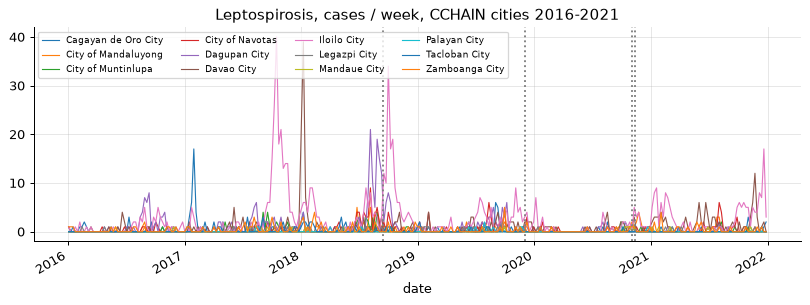

[cchain] Open city-week LEPTOSPIROSIS series exists (PIDSR via CCHAIN, 12 cities, 2008-2022). The proposal's 'no open subnational lepto series' is outdated; lepto can be a sub-national stretch goal without digitising DOH reports.


In [5]:
lep = cc[cc.disease_common_name == "LEPTOSPIROSIS"].pivot_table(index="date", columns="adm3_en", values="case_total", aggfunc="sum")
ax = lep.loc["2016":"2021"].plot(figsize=(11, 3.5), lw=.9, legend=False, title="Leptospirosis, cases / week, CCHAIN cities 2016-2021")
for d in ["2018-09-15", "2019-12-02", "2020-11-01", "2020-11-11"]: ax.axvline(pd.Timestamp(d), color="grey", ls=":")
ax.legend(fontsize=7, ncol=4, loc="upper left"); plt.show()
note("cchain", f"Open city-week LEPTOSPIROSIS series exists (PIDSR via CCHAIN, {cc.adm3_en.nunique()} cities, 2008-2022). The proposal's 'no open subnational lepto series' is outdated; lepto can be a sub-national stretch goal without digitising DOH reports.")

## 3. Mendeley Parreño national weekly notifiable diseases

(52, 101) | diseases: 20 | years: [2019, 2020, 2021, 2022, 2023]


year,2019,2020,2021,2022,2023
disease,,,,,
Dengue,52,28,52,52,42
Leptospirosis,52,28,52,52,43


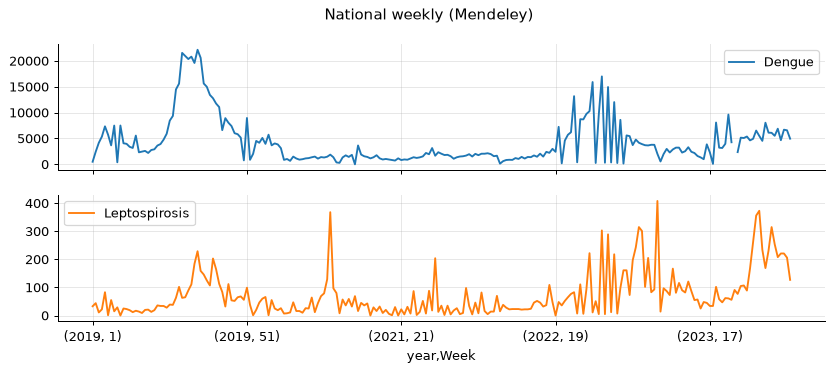

[mendeley_parreno] National weekly only, years [2019, 2020, 2021, 2022, 2023]; 2020 weeks present: 28/52. Does not cover 2016-2018, so it cannot cross-check Ompong (2018).


In [6]:
mx = pd.read_excel(RAW / "mendeley_parreno/Diseases_Data_for_NBL.xlsx")
long = mx.melt(id_vars="Week", var_name="col", value_name="cases")
long[["disease", "year"]] = long.col.str.rsplit(" - ", n=1, expand=True); long.year = long.year.astype(int)
print(mx.shape, "| diseases:", long.disease.nunique(), "| years:", sorted(long.year.unique().tolist()))
cov = long.assign(present=long.cases.notna()).pivot_table(index="disease", columns="year", values="present", aggfunc="sum")
display(cov.loc[["Dengue", "Leptospirosis"]])
sub = long[long.disease.isin(["Dengue", "Leptospirosis"])].pivot_table(index=["year", "Week"], columns="disease", values="cases")
sub.plot(subplots=True, figsize=(11, 4), title="National weekly (Mendeley)", legend=True); plt.show()
note("mendeley_parreno", f"National weekly only, years {sorted(long.year.unique().tolist())}; 2020 weeks present: {int(cov.loc['Dengue', 2020])}/52. Does not cover 2016-2018, so it cannot cross-check Ompong (2018).")

## 4. OpenDengue V1.3 (Philippines)

In [7]:
z = zipfile.ZipFile(RAW / "opendengue/Temporal_extract_V1_3.zip")
od = pd.read_csv(z.open([n for n in z.namelist() if n.endswith(".csv")][0]), low_memory=False)
od = od[od.adm_0_name.str.upper() == "PHILIPPINES"].assign(start=lambda d: pd.to_datetime(d.calendar_start_date))
display(od.groupby(["S_res", "T_res"]).agg(rows=("dengue_total", "size"), first=("Year", "min"), last=("Year", "max")))
nat = od[(od.S_res == "Admin0") & (od.T_res == "Week")].set_index("start").dengue_total.sort_index()
hdx_nat = dg.groupby("date").cases.sum()
j = pd.concat([nat.rename("opendengue"), hdx_nat.rename("doh_hdx")], axis=1).loc["2016":"2020"].dropna()
print(f"overlapping weeks 2016-2020: {len(j)}; correlation {j.corr().iloc[0,1]:.3f}; ratio OD/HDX median {(j.opendengue/j.doh_hdx).median():.2f}")
note("opendengue", "V1.3 exists (May 2025). PHL = national weekly 2012-2023, region yearly to 2021, province monthly only 1994-2010; useful only as a national cross-check.")

rows  first  last
S_res  T_res                   
Admin0 Month    22   2011  2013
       Week    544   2012  2023
       Year     59   1955  2019
Admin1 Month  1431   1994  2010
       Year    224   2000  2021
Admin2 Month  9060   1994  2010

overlapping weeks 2016-2020: 246; correlation 0.947; ratio OD/HDX median 0.93
[opendengue] V1.3 exists (May 2025). PHL = national weekly 2012-2023, region yearly to 2021, province monthly only 1994-2010; useful only as a national cross-check.


## 5. Boundaries (COD-AB) and 2020 census: join-key check

In [8]:
import pyogrio
zpath = f"zip://{(RAW / 'cod_ab/phl_admin_boundaries.gdb.zip').as_posix()}"
print(pyogrio.list_layers(zpath))
adm1 = gpd.read_file(zpath, layer="phl_admin1")
adm2 = gpd.read_file(zpath, layer="phl_admin2")
adm3 = gpd.read_file(zpath, layer="phl_admin3", read_geometry=False)
print("ADM1", len(adm1), "| ADM2", len(adm2), "| ADM3", len(adm3), "| version:", adm2.version.iloc[0], "valid_on:", adm2.valid_on.iloc[0])
print(sorted(adm2.adm2_name))

[['phl_admin0' 'MultiPolygon']
 ['phl_admin1' 'MultiPolygon']
 ['phl_admin2' 'MultiPolygon']
 ['phl_admin3' 'MultiPolygon']
 ['phl_admin4' 'MultiPolygon']
 ['phl_adminlines' 'MultiLineString']
 ['phl_adminpoints' 'Point']]


ADM1 17 | ADM2 88 | ADM3 1642 | version: v03 valid_on: 2025-02-13 00:00:00
['Abra', 'Agusan del Norte', 'Agusan del Sur', 'Aklan', 'Albay', 'Antique', 'Apayao', 'Aurora', 'Basilan', 'Bataan', 'Batanes', 'Batangas', 'Benguet', 'Biliran', 'Bohol', 'Bukidnon', 'Bulacan', 'Cagayan', 'Camarines Norte', 'Camarines Sur', 'Camiguin', 'Capiz', 'Catanduanes', 'Cavite', 'Cebu', 'City of Isabela (not a province)', 'Cotabato (North Cotabato)', 'Davao Occidental', 'Davao Oriental', 'Davao de Oro (Compostela Valley)', 'Davao del Norte', 'Davao del Sur', 'Dinagat Islands', 'Eastern Samar', 'Guimaras', 'Ifugao', 'Ilocos Norte', 'Ilocos Sur', 'Iloilo', 'Isabela', 'Kalinga', 'La Union', 'Laguna', 'Lanao del Norte', 'Lanao del Sur', 'Leyte', 'Maguindanao del Norte', 'Maguindanao del Sur', 'Marinduque', 'Masbate', 'Metropolitan Manila First District', 'Metropolitan Manila Fourth District', 'Metropolitan Manila Second District', 'Metropolitan Manila Third District', 'Misamis Occidental', 'Misamis Oriental',

In [9]:
import unicodedata
def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()  # Las Piñas -> LAS PINAS
    s = re.sub(r"\(.*?\)", "", s)
    return re.sub(r"[^A-Z]", "", s.replace("CITY OF ", "").replace(" CITY", ""))
# dengue spellings / old units -> COD-AB names (normalised). BASILIG CITY is in CARAGA, i.e. Bislig City; Maguindanao was split in 2022
fix = {"NUEVAVISCAYA": "NUEVAVIZCAYA", "SISQUIJOR": "SIQUIJOR", "NORTHCOTABATO": "COTABATO", "BASILIG": "BISLIG",
       "MAGUINDANAO": "MAGUINDANAODELNORTE", "MANILA": "METROPOLITANMANILAFIRSTDISTRICT"}
a2 = {norm(n): n for n in adm2.adm2_name if not n.startswith("City of Isabela")}  # else it collides with Isabela province
a3 = adm3.assign(k=adm3.adm3_name.map(norm), city=adm3.adm3_name.str.contains("City"))
dup = a3[a3.city].k.value_counts(); dup = set(dup[dup > 1].index)  # names shared by two cities
a3 = a3.sort_values("city", ascending=False, kind="stable").drop_duplicates("k").set_index("k")  # city beats same-name town
rows = []
for l in sorted(dg["loc"].unique()):
    k = fix.get(norm(l), norm(l))
    if l in cities and k in a3.index: rows.append((l, "ADM3 city -> ADM2", a3.loc[k, "adm2_name"], a3.loc[k, "adm3_name"]))  # Quezon City != Quezon
    elif k in a2: rows.append((l, "ADM2", a2[k], None))
    elif k in a3.index: rows.append((l, "ADM3 -> ADM2", a3.loc[k, "adm2_name"], a3.loc[k, "adm3_name"]))
    else: rows.append((l, "UNMATCHED", None, None))
m = pd.DataFrame(rows, columns=["dengue_loc", "level", "adm2", "adm3"])
print(m.level.value_counts().to_dict()); display(m[m.level == "UNMATCHED"])
print("ambiguous city names, check by region:", m[m.dengue_loc.map(lambda l: fix.get(norm(l), norm(l))).isin(dup)].to_dict("records"))
unused = sorted(set(adm2.adm2_name) - set(m.adm2.dropna()))
print(f"COD-AB ADM2 units with no dengue unit mapped ({len(unused)}):", unused)
note("cod_ab", f"COD-AB is current-boundary ({len(adm2)} ADM2: 4 NCR districts, Maguindanao del Norte/Sur split 2022, Special Geographic Area 2024). The 2016-2020 dengue units need a harmonised historical crosswalk. Name match: {(m.level!='UNMATCHED').sum()}/{len(m)} units (BASILIG CITY = Bislig City, CARAGA). PSA PSGC 2Q 2026 must be downloaded manually (psa.gov.ph blocks scripts).")

{'ADM2': 82, 'ADM3 city -> ADM2': 44}


,dengue_loc,level,adm2,adm3


ambiguous city names, check by region: [{'dengue_loc': 'NAGA CITY', 'level': 'ADM3 city -> ADM2', 'adm2': 'Camarines Sur', 'adm3': 'Naga City'}]
COD-AB ADM2 units with no dengue unit mapped (2): ['Maguindanao del Sur', 'Special Geographic Area']
[cod_ab] COD-AB is current-boundary (88 ADM2: 4 NCR districts, Maguindanao del Norte/Sur split 2022, Special Geographic Area 2024). The 2016-2020 dengue units need a harmonised historical crosswalk. Name match: 126/126 units (BASILIG CITY = Bislig City, CARAGA). PSA PSGC 2Q 2026 must be downloaded manually (psa.gov.ph blocks scripts).


In [10]:
if have("census2020"):
    cx = pd.ExcelFile(RAW / "census2020/2020_CPH_SexAge_Popn_Mun_Admin3.xlsx"); print(cx.sheet_names)
    cph = pd.read_excel(cx, cx.sheet_names[0]); print(cph.shape); display(cph.head(3))

['AgeGroup', 'PopnMun', 'muncode lookup']


(27795, 8)


,Region,Province,Municipality,Muncode,Age_Group,Popn Male,Popn Female,Popn Total
0,Region I (Ilocos Region),ILOCOS NORTE,ADAMS,PH012801000,0 - 4,110,115,225
1,Region I (Ilocos Region),ILOCOS NORTE,ADAMS,PH012801000,5 - 9,135,103,238
2,Region I (Ilocos Region),ILOCOS NORTE,ADAMS,PH012801000,10 - 14,106,104,210


## 6. IBTrACS typhoon tracks (backtest storms)

,sid,fixes,start,end,max_wind_kt,r34_coverage
local,,,,,,
Ompong,2018250N12170,99,2018-09-06 12:00:00,2018-09-17 18:00:00,155.0,0.85
Rolly,2020299N11144,97,2020-10-25 06:00:00,2020-11-06 06:00:00,170.0,0.42
Tisoy,2019329N09160,97,2019-11-24 12:00:00,2019-12-06 12:00:00,120.0,0.71
Ulysses,2020313N08135,67,2020-11-08 00:00:00,2020-11-16 06:00:00,115.0,0.69


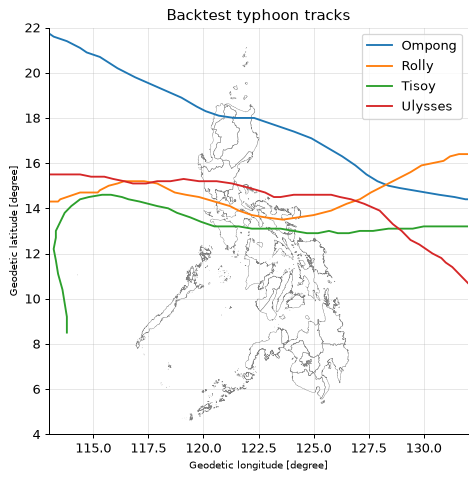

WP storms per season 2016-2020: {2016: 32, 2017: 34, 2018: 37, 2019: 32, 2020: 28}
[ibtracs] All 4 storms present; USA 34-kt radius available on 42%-85% of fixes, so the gale-radius buffer needs a fallback (e.g. TOKYO_R30 or a fixed radius).


In [11]:
ib = pd.read_csv(RAW / "ibtracs/ibtracs.WP.list.v04r01.csv", skiprows=[1], low_memory=False, na_values=[" "])
STORMS = {("MANGKHUT", 2018): "Ompong", ("KAMMURI", 2019): "Tisoy", ("GONI", 2020): "Rolly", ("VAMCO", 2020): "Ulysses"}
tr = ib[[(n, s) in STORMS for n, s in zip(ib.NAME, ib.SEASON)]].copy()
tr["local"] = tr.apply(lambda r: STORMS[(r.NAME, r.SEASON)], axis=1); tr["ISO_TIME"] = pd.to_datetime(tr.ISO_TIME)
r34 = ["USA_R34_NE", "USA_R34_SE", "USA_R34_SW", "USA_R34_NW"]
s = tr.groupby("local").agg(sid=("SID", "first"), fixes=("ISO_TIME", "size"), start=("ISO_TIME", "min"), end=("ISO_TIME", "max"),
                            max_wind_kt=("USA_WIND", "max"), r34_coverage=("USA_R34_NE", lambda x: x.notna().mean().round(2)))
display(s)
fig, ax = plt.subplots(figsize=(6, 7)); adm1.boundary.plot(ax=ax, lw=.3, color="grey")
for n, g in tr.groupby("local"): ax.plot(g.LON, g.LAT, lw=1.5, label=n)
ax.set(xlim=(113, 132), ylim=(4, 22), title="Backtest typhoon tracks"); ax.legend(); plt.show()
print("WP storms per season 2016-2020:", ib[ib.SEASON.between(2016, 2020)].groupby("SEASON").SID.nunique().to_dict())
note("ibtracs", f"All 4 storms present; USA 34-kt radius available on {s.r34_coverage.min():.0%}-{s.r34_coverage.max():.0%} of fixes, so the gale-radius buffer needs a fallback (e.g. TOKYO_R30 or a fixed radius).")

## 7. Rainfall: CHIRPS (open) and IMERG (GEE)

{'T': 1827, 'Y': 350, 'X': 220} mm/day | 2016-01-01 -> 2020-12-31


days: 1827 | missing days: 0 | land cells: 14781 | NaN share on land: 0.0


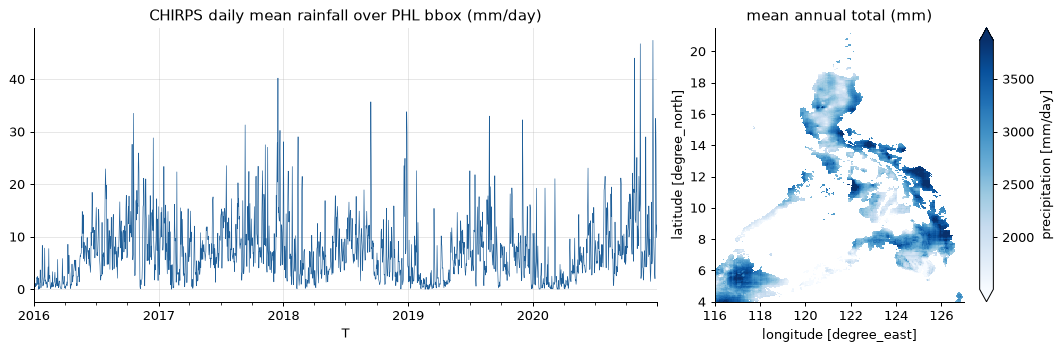

[chirps] CHIRPS v2.0 daily, 2016-01-01 to 2020-12-31 (1827 days, 0 missing), land only (sea is NaN); time axis is julian_day and must be converted.


60 monthly stacks | (177, 111) (0.10000045742818513, 0.10000045742818513) | days: 1827 2016-01-01 -> 2020-12-31
daily bbox-mean correlation with CHIRPS: 0.79 (IMERG covers sea too, so levels differ)
[imerg] IMERG V07 daily via GEE: 1827 days 2016-01-01 to 2020-12-31, 0.1 deg; one GeoTIFF per month, band i = day i (no band names in the file).


In [12]:
import xarray as xr
if have("chirps"):
    ch = xr.open_mfdataset(sorted((RAW / "chirps").glob("*.nc")), decode_times=False, combine="by_coords")
    assert ch["T"].attrs["units"] == "julian_day"  # IRI convention; 2440587.5 = 1970-01-01
    ch = ch.assign_coords(T=pd.to_datetime(ch["T"].values - 2440587.5, unit="D").normalize())
    pr = ch.prcp; print(dict(pr.sizes), pr.attrs["units"], "|", str(pr["T"].values[0])[:10], "->", str(pr["T"].values[-1])[:10])
    daily = pr.mean(["X", "Y"]).to_series(); land = pr.isel(T=0).notnull()
    gaps = pd.date_range(daily.index.min(), daily.index.max()).difference(daily.index)
    print("days:", len(daily), "| missing days:", len(gaps), "| land cells:", int(land.sum()), "| NaN share on land:", round(float(pr.where(land).isnull().mean() - (~land).mean()), 4))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
    daily.plot(ax=ax[0], lw=.5, color="#1f5f99", title="CHIRPS daily mean rainfall over PHL bbox (mm/day)")
    (pr.sum("T", min_count=1) / (len(daily) / 365.25)).plot(ax=ax[1], cmap="Blues", robust=True); ax[1].set_title("mean annual total (mm)")
    plt.tight_layout(); plt.show()
    note("chirps", f"CHIRPS v2.0 daily, {daily.index.min().date()} to {daily.index.max().date()} ({len(daily)} days, {len(gaps)} missing), land only (sea is NaN); time axis is julian_day and must be converted.")
if have("imerg"):
    import rasterio
    fs = sorted((RAW / "imerg").glob("*.tif")); im = {}
    for f in fs:
        with rasterio.open(f) as r:
            a = r.read(masked=True)  # band i = day i of the month; the GeoTIFF keeps no band names
            im.update(dict(zip(pd.date_range(pd.to_datetime(f.stem[-6:], format="%Y%m"), periods=r.count), a.mean(axis=(1, 2)).filled(np.nan))))
    im = pd.Series(im).sort_index(); print(len(fs), "monthly stacks |", r.shape, r.res, "| days:", len(im), im.index.min().date(), "->", im.index.max().date())
    both = pd.concat([im.rename("imerg"), daily.rename("chirps")], axis=1).dropna() if "daily" in dir() else None
    if both is not None: print(f"daily bbox-mean correlation with CHIRPS: {both.corr().iloc[0, 1]:.2f} (IMERG covers sea too, so levels differ)")
    note("imerg", f"IMERG V07 daily via GEE: {len(im)} days {im.index.min().date()} to {im.index.max().date()}, 0.1 deg; one GeoTIFF per month, band i = day i (no band names in the file).")

## 8. Flood: Copernicus EMS, NOAH hazard, GFD / Sentinel-1 (GEE)

In [13]:
def read_zip_layers(z, pattern):
    out = []
    for n in zipfile.ZipFile(z).namelist():
        if re.search(pattern, n, re.I) and n.endswith((".shp", ".json", ".geojson")):
            g = gpd.read_file(f"zip://{Path(z).as_posix()}!{n}"); g["layer"] = Path(n).stem; g["file"] = Path(z).name; out.append(g)
    return out
for act in ["EMSR312", "EMSR478"]:
    zs = sorted((RAW / "copernicus_ems" / act).glob("*.zip")); print(f"{act}: {len(zs)} vector packages")
    for z in zs[:1]: print("  layers in", z.name, ":", [Path(n).stem for n in zipfile.ZipFile(z).namelist() if n.endswith((".shp", ".json"))])
obs = [g for z in sorted((RAW / "copernicus_ems/EMSR312").glob("*DELINEATION*.zip")) for g in read_zip_layers(z, r"observed.?event")]
if obs:
    fl = pd.concat([g.to_crs(32651) for g in obs]); fl["km2"] = fl.area / 1e6
    fl[["aoi", "product"]] = fl.file.str.extract(r"EMSR312_\d+(\w+?)_01DELINEATION_(\w+?)_v")  # MAP = first pass, MONIT01 = later re-map of the same AOI
    km = fl.pivot_table(index="aoi", columns="product", values="km2", aggfunc="sum").round(1); display(km)
    note("copernicus_ems", f"EMSR312 (Ompong) observed flood, {len(km)} Northern Luzon AOIs: {km['MAP'].sum():.0f} km2 at first delineation, {km['MONIT01'].sum():.0f} km2 at monitoring (same AOIs, don't add).")
note("copernicus_ems", "EMSR478 (Rolly) has only damage-GRADING products (4 AOIs), no flood delineation; it cannot cross-check Sentinel-1 flood extent as the proposal states.")

EMSR312: 12 vector packages
  layers in EMSR312_05TUGUEGARAO_01DELINEATION_MAP_v1_vector.zip : ['EMSR312_05TUGUEGARAO_DEL_v1_area_of_interest_a', 'EMSR312_05TUGUEGARAO_DEL_v1_built_up_a', 'EMSR312_05TUGUEGARAO_DEL_v1_hydrography_a', 'EMSR312_05TUGUEGARAO_DEL_v1_hydrography_l', 'EMSR312_05TUGUEGARAO_DEL_v1_image_footprint_a', 'EMSR312_05TUGUEGARAO_DEL_v1_observed_event_a', 'EMSR312_05TUGUEGARAO_DEL_v1_transportation_l', 'EMSR312_05TUGUEGARAO_DEL_v1_transportation_p']
EMSR478: 4 vector packages
  layers in EMSR478_AOI01_GRA_PRODUCT_r1_RTP01_v1_vector.zip : ['EMSR478_AOI01_GRA_PRODUCT_areaOfInterestA_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_areaOfInterestA_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_builtUpP_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_builtUpP_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_hydrographyA_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_hydrographyA_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_hydrographyL_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_hydrographyL_r1_v1', 'EMSR478_AOI01_GRA_PRODUCT_imageFootprintA_r1_v1', 'EMSR

product,MAP,MONIT01
aoi,,
APARRI,19.1,29.8
CANDON,4.3,6.8
ILAGAN,7.2,23.8
SUDIPEN,6.1,9.3
TUGUEGARAO,5.2,40.6
VIGAN,6.4,10.1


[copernicus_ems] EMSR312 (Ompong) observed flood, 6 Northern Luzon AOIs: 48 km2 at first delineation, 120 km2 at monitoring (same AOIs, don't add).
[copernicus_ems] EMSR478 (Rolly) has only damage-GRADING products (4 AOIs), no flood delineation; it cannot cross-check Sentinel-1 flood extent as the proposal states.


5yr 67 province files, 2183 MB
25yr 72 province files, 2550 MB
example: Albay.zip ['Albay/PH050500000_FH_25yr.shp']


['Var', 'geometry'] EPSG:4326


Var
1.0    72.2
2.0    89.3
3.0    45.2
Name: km2, dtype: float64

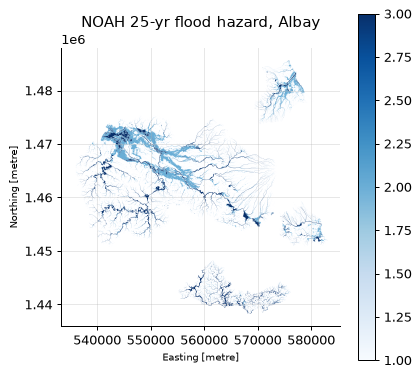

5yr: 71/88 ADM2 with a map; unmatched: []


25yr: 75/88 ADM2 with a map; unmatched: []
no 25-yr map: ['Basilan', 'Batanes', 'Biliran', 'Camiguin', 'City of Isabela (not a province)', 'Davao Occidental', 'Guimaras', 'Northern Samar', 'Romblon', 'Siquijor', 'Special Geographic Area', 'Sulu', 'Tawi-Tawi']
[noah] NOAH 5-yr: 67 files, 25-yr: 72 files, from the UP NOAH Google Drive, not LiPAD. 25-yr maps cover 75/88 COD-AB ADM2 units; none for Basilan, Batanes, Biliran, Camiguin, City of Isabela (not a province), Davao Occidental, Guimaras, Northern Samar, Romblon, Siquijor, Special Geographic Area, Sulu, Tawi-Tawi. Carry these as missing, not zero hazard.


In [14]:
for rp in ["5yr", "25yr"]:
    if have("noah", rp):
        zs = sorted((RAW / "noah" / rp).glob("*.zip")); print(rp, len(zs), "province files,", round(sum(z.stat().st_size for z in zs) / 1e6), "MB")
z = sorted((RAW / "noah/25yr").glob("Albay*.zip"))[0]
shp = [n for n in zipfile.ZipFile(z).namelist() if n.endswith(".shp")]; print("example:", z.name, shp)
nz = gpd.read_file(f"zip://{z.as_posix()}!{shp[0]}"); print(nz.columns.tolist(), nz.crs)
vcol = [c for c in nz.columns if c.lower() in ("var", "haz", "hazard", "class")][0]
nz = nz.to_crs(32651); display(nz.assign(km2=nz.area / 1e6).groupby(vcol).km2.sum().round(1))
nz.plot(column=vcol, cmap="Blues", figsize=(5, 5), legend=True); plt.title("NOAH 25-yr flood hazard, Albay"); plt.show()
# which COD-AB provinces have a map? shapefiles are named by province (CamelCase) or by old 9-digit PSGC (PH050500000)
nk = lambda s: re.sub(r"[^A-Z]", "", re.sub(r"\(.*?\)", "", s.upper()))
a2n = {nk(n): [n] for n in adm2.adm2_name} | {nk(n.split("(")[1]): [n] for n in adm2.adm2_name if "(" in n and "not a" not in n}
a2n |= {"MAGUINDANAO": ["Maguindanao del Norte", "Maguindanao del Sur"], "MINDORO": ["Occidental Mindoro", "Oriental Mindoro"],
        "METROMANILA": [n for n in adm2.adm2_name if n.startswith("Metropolitan Manila")]}  # pre-split / multi-province files
by_pc = dict(zip(adm2.adm2_pcode, adm2.adm2_name))
cover = {}
for rp in ["5yr", "25yr"]:
    got = set()
    for z in (RAW / "noah" / rp).glob("*.zip"):
        for st in (Path(n).stem for n in zipfile.ZipFile(z).namelist() if n.endswith(".shp")):
            pc = re.match(r"PH(\d{2})(\d{2})\d{5}", st)
            got |= {by_pc[f"PH{pc[1]}0{pc[2]}"]} if pc else set(a2n.get(nk(re.split(r"_(?:Flood|FH)", st)[0]), [f"?{st}"]))
    cover[rp] = got; print(f"{rp}: {len(got & set(adm2.adm2_name))}/{len(adm2)} ADM2 with a map; unmatched:", sorted(g for g in got if g.startswith("?")))
nomap = sorted(set(adm2.adm2_name) - cover["25yr"]); print("no 25-yr map:", nomap)
note("noah", f"NOAH 5-yr: {len(list((RAW/'noah/5yr').glob('*.zip')))} files, 25-yr: {len(list((RAW/'noah/25yr').glob('*.zip')))} files, from the UP NOAH Google Drive, not LiPAD. 25-yr maps cover {len(adm2) - len(nomap)}/{len(adm2)} COD-AB ADM2 units; none for {', '.join(nomap)}. Carry these as missing, not zero hazard.")


In [15]:
if have("gfd"):
    gfd = pd.read_csv(RAW / "gfd/gfd_events_phl.csv")
    gfd[["began", "ended"]] = gfd.system_index.str.extract(r"From_(\d{8})_to_(\d{8})").apply(pd.to_datetime)  # began/ended props come back empty
    phl = gfd[gfd.cc.str.contains("PHL", na=False)]
    print(len(gfd), "GFD events intersecting PHL bbox,", len(phl), "tagged PHL"); display(phl.tail(3)[["system_index", "dfo_main_cause", "dfo_dead", "dfo_displaced"]])
    note("gfd", f"Global Flood Database: {len(phl)} PHL events, {phl.began.min().date()} to {phl.ended.max().date()}; none for Ompong (Sep 2018) or later, so it can't validate any backtest storm.")
if have("sentinel1"):
    s1 = pd.read_csv(RAW / "sentinel1/s1_scene_inventory.csv"); s1["t"] = pd.to_datetime(s1.time_ms, unit="ms")
    s1["phase"] = np.where(s1.t < pd.to_datetime(s1.landfall), "before", "after"); display(s1.pivot_table(index="typhoon", columns="phase", values="scene", aggfunc="count"))

62 GFD events intersecting PHL bbox, 44 tagged PHL


,system_index,dfo_main_cause,dfo_dead,dfo_displaced
58,DFO_4300_From_20151022_to_20151028,Tropical Storm Koppu,54,60000
59,DFO_4318_From_20151212_to_20160106,"Tropical storms Melor, Onyok",40,20000
60,DFO_4485_From_20170612_to_20170614,Heavy Rain,0,0


[gfd] Global Flood Database: 44 PHL events, 2002-07-06 to 2017-06-14; none for Ompong (Sep 2018) or later, so it can't validate any backtest storm.


phase,after,before
typhoon,,
Ompong_Mangkhut_2018,93,130
Rolly_Goni_2020,100,160
Tisoy_Kammuri_2019,83,154
Ulysses_Vamco_2020,94,165


## 9. HydroRIVERS (Philippines clip)

41097 reaches in PHL (51,107 in bbox) | ['HYRIV_ID', 'NEXT_DOWN', 'MAIN_RIV', 'LENGTH_KM', 'DIST_DN_KM', 'DIST_UP_KM', 'CATCH_SKM', 'UPLAND_SKM', 'ENDORHEIC', 'DIS_AV_CMS', 'ORD_STRA', 'ORD_CLAS', 'ORD_FLOW', 'HYBAS_L12', 'geometry']
outlets (NEXT_DOWN==0): 4065 | ORD_STRA dist: {1: 22982, 2: 10202, 3: 4843, 4: 2180, 5: 609, 6: 199, 7: 82}


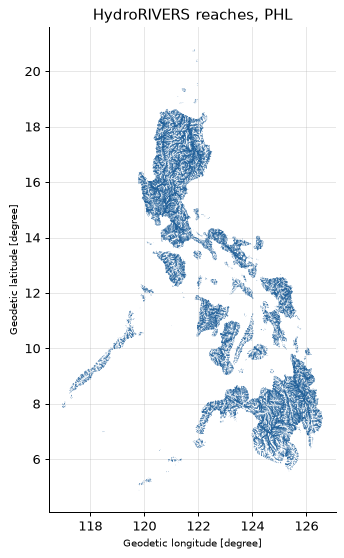

[hydrorivers] 41,097 PHL reaches (4,065 outlets, so many short independent island basins). The Philippines is in the HydroSHEDS Australasia (au) file; the Asia (as) file has none.


In [16]:
hr = gpd.read_file(f"zip://{(RAW / 'hydrorivers/HydroRIVERS_v10_au_shp.zip').as_posix()}!HydroRIVERS_v10_au_shp/HydroRIVERS_v10_au.shp", bbox=BBOX)
n_bbox = len(hr)  # the bbox also catches Borneo/Sulawesi reaches; keep those touching PHL (simplified outline, fast)
land = gpd.read_file(zpath, layer="phl_admin0").to_crs(hr.crs).simplify(0.01).buffer(0.01).union_all()
hr = hr[hr.intersects(land)]
print(len(hr), f"reaches in PHL ({n_bbox:,} in bbox) |", hr.columns.tolist())
print("outlets (NEXT_DOWN==0):", (hr.NEXT_DOWN == 0).sum(), "| ORD_STRA dist:", hr.ORD_STRA.value_counts().sort_index().to_dict())
ax = hr.plot(linewidth=hr.ORD_STRA / 4, figsize=(6, 7), color="#1f5f99"); ax.set_title("HydroRIVERS reaches, PHL"); plt.show()
note("hydrorivers", f"{len(hr):,} PHL reaches ({(hr.NEXT_DOWN == 0).sum():,} outlets, so many short independent island basins). The Philippines is in the HydroSHEDS Australasia (au) file; the Asia (as) file has none.")


## 10. Access network: OSM, RoRo routes, health facilities, friction

(108, 16)


,to_prov,from_prov,route_name,dist_nm,avg_time_hrs,freq_daily,pax_cap,cargo_cap,marina_code,highway_type,from_lat,from_lon,from_region,to_lat,to_lon,to_region
1,AgusandelNorte,MisamisOriental,CagayanDeOro-Nasipit,65.0,6.0,2.0,1000.0,80.0,CNH-09,Central,8.4800,124.6500,Mindanao,9.0000,125.500,Mindanao
2,Aklan,OrientalMindoro,Roxas-Caticlan,42.0,4.0,8.0,300.0,25.0,WNH-02,Western,13.4116,121.1814,Luzon,11.7061,122.365,Visayas
3,Aklan,Palawan,Cuyo-Roxas,65.0,6.0,2.0,300.0,25.0,MR-10,Missionary,9.7400,118.7400,Luzon,11.7061,122.365,Visayas
4,Antique,Romblon,Odiongan-Lipata,42.0,4.0,4.0,200.0,15.0,MR-08,Missionary,12.5000,122.2000,Luzon,11.0000,122.100,Visayas
5,Antique,Palawan,Cuyo-SanJose,55.0,5.0,2.0,300.0,25.0,MR-30,Missionary,9.7400,118.7400,Luzon,11.0000,122.100,Visayas


provinces in RoRo network: 40 | highway_type: {'Missionary': 60, 'Central': 20, 'Western': 18, 'Eastern': 10}


,dist_nm,avg_time_hrs,freq_daily
count,108.0,108.0,108.0
mean,49.6,4.6,6.2
std,38.6,3.8,7.7
min,5.0,0.5,0.1
25%,28.0,2.5,2.0
50%,41.0,3.8,4.0
75%,55.0,5.5,6.0
max,210.0,20.0,48.0


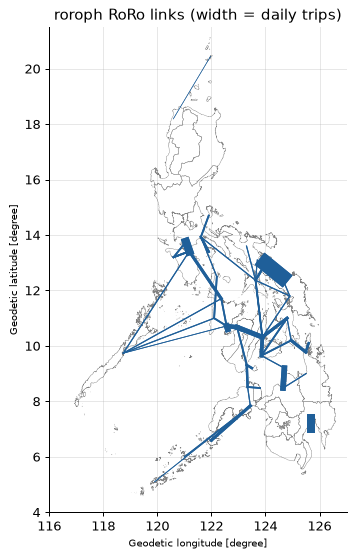

[roroph] 108 routes across 40 provinces, with GADM-style names (e.g. 'AgusandelNorte'), so a name crosswalk is needed. Port coordinates are coarse (33% of port coordinates sit on a 0.1 deg grid) and need snapping to OSM ports. Routes describe 2024-2026 operations, so they are a proxy for 2018-2020.


In [17]:
import rdata
rr = rdata.read_rda(RAW / "roroph/roro_routes.rda")["roro_routes"]; print(rr.shape); display(rr.head())
provs = pd.unique(rr[["from_prov", "to_prov"]].values.ravel()); print("provinces in RoRo network:", len(provs), "| highway_type:", rr.highway_type.value_counts().to_dict())
display(rr[["dist_nm", "avg_time_hrs", "freq_daily"]].describe().round(1))
xy = rr[["from_lat", "from_lon", "to_lat", "to_lon"]].to_numpy() * 10
coarse = np.isclose(xy, xy.round()).mean()  # share of port coordinates on a 0.1 deg grid
fig, ax = plt.subplots(figsize=(6, 7)); adm1.boundary.plot(ax=ax, lw=.3, color="grey")
for _, r in rr.iterrows(): ax.plot([r.from_lon, r.to_lon], [r.from_lat, r.to_lat], color="#1f5f99", lw=.4 + r.freq_daily / 4)
ax.set(xlim=(116, 127), ylim=(4, 21.5), title="roroph RoRo links (width = daily trips)"); plt.show()
note("roroph", f"{len(rr)} routes across {len(provs)} provinces, with GADM-style names (e.g. 'AgusandelNorte'), so a name crosswalk is needed. Port coordinates are coarse ({coarse:.0%} of port coordinates sit on a 0.1 deg grid) and need snapping to OSM ports. Routes describe 2024-2026 operations, so they are a proxy for 2018-2020.")

In [18]:
pbf = RAW / "osm/philippines-latest.osm.pbf"
if have("osm", "philippines-latest.osm.pbf"):
    print(f"PBF {pbf.stat().st_size/1e6:.0f} MB; OSM layers:", pyogrio.list_layers(pbf.as_posix()))
    roads = pyogrio.read_dataframe(pbf.as_posix(), layer="lines", columns=["highway", "other_tags"], read_geometry=False)
    print("lines:", len(roads))
    hw = roads.highway.value_counts(); display(hw.head(15))
    ferries = roads.other_tags.fillna("").str.contains('"route"=>"ferry"').sum()
    note("osm", f"Geofabrik PBF has {hw.sum():,} highway ways ({hw[['motorway','trunk','primary','secondary']].sum():,} motorway-secondary) and {ferries} route=ferry lines; it is a current snapshot, not a 2018-2020 one.")

PBF 611 MB; OSM layers: [['points' 'Point']
 ['lines' 'LineString']
 ['multilinestrings' 'MultiLineString']
 ['multipolygons' 'MultiPolygon']
 ['other_relations' 'GeometryCollection']]


lines: 1940134


highway
residential     719333
service         328137
track           116068
unclassified    108436
path            103677
footway          86729
tertiary         62016
secondary        29172
primary          24347
trunk            15363
steps             7142
pedestrian        3172
proposed          3047
motorway          2934
construction      2719
Name: count, dtype: int64

[osm] Geofabrik PBF has 1,621,184 highway ways (71,816 motorway-secondary) and 1136 route=ferry lines; it is a current snapshot, not a 2018-2020 one.


HOT OSM: (19129, 25)


amenity
pharmacy       7100
clinic         2921
hospital       2026
dentist        1910
doctors        1566
health_post    1555
laboratory       49
veterinary       15
Name: count, dtype: int64

NOAH facilities: (20051, 3) {'hospital': 20051}


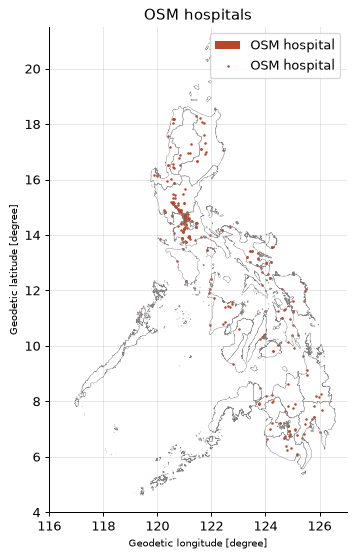

[hospitals] DOH NHFR blocks scripted access (403) - must be downloaded manually. Open fallbacks: HOT OSM (2026 hospitals) and NOAH critical facilities (20,051 points, name only, no level/bed data).
friction_surface_2019_motorized_phl.tif (2112, 1321) | water/fill value 3.16 min/km on 84% of cells | land median 3.0 min/km


friction_surface_2019_walking_phl.tif (2112, 1321) | water/fill value 60.00 min/km on 83% of cells | land median 18.9 min/km
[map_friction] MAP friction 2019 (motorised + walking) via GEE, ~1 km, min/m. Sea is a constant value (~83% of bbox cells), not nodata: mask it before computing access.


In [19]:
hz = zipfile.ZipFile(RAW / "hotosm_health/hotosm_phl_health_facilities_osm_gpkg.zip"); gp = [n for n in hz.namelist() if n.endswith(".gpkg")][0]
hf = gpd.read_file(f"zip://{(RAW / 'hotosm_health/hotosm_phl_health_facilities_osm_gpkg.zip').as_posix()}!{gp}")
print("HOT OSM:", hf.shape); display(hf.amenity.value_counts().head(8) if "amenity" in hf else hf.columns)
nf = gpd.read_file(RAW / "noah_facilities/hospitals.geojson"); print("NOAH facilities:", nf.shape, nf.amenity.value_counts().to_dict())
fig, ax = plt.subplots(figsize=(6, 7)); adm1.boundary.plot(ax=ax, lw=.3, color="grey")
hf[hf.get("amenity", "") == "hospital"].plot(ax=ax, markersize=1, color="#b5482b", label="OSM hospital")
ax.set(xlim=(116, 127), ylim=(4, 21.5), title="OSM hospitals"); ax.legend(); plt.show()
note("hospitals", f"DOH NHFR blocks scripted access (403) - must be downloaded manually. Open fallbacks: HOT OSM ({(hf.get('amenity','')=='hospital').sum()} hospitals) and NOAH critical facilities ({len(nf):,} points, name only, no level/bed data).")
if have("map_friction"):
    import rasterio
    for f in sorted((RAW / "map_friction").glob("*.tif")):
        with rasterio.open(f) as r: a = r.read(1, masked=True)
        v, n = np.unique(a.compressed().round(6), return_counts=True); water = v[n.argmax()]  # sea is one constant value, not nodata
        print(f"{f.name} {r.shape} | water/fill value {water * 1000:.2f} min/km on {n.max() / a.count():.0%} of cells | land median {np.median(a.compressed()[a.compressed().round(6) != water]) * 1000:.1f} min/km")
    note("map_friction", "MAP friction 2019 (motorised + walking) via GEE, ~1 km, min/m. Sea is a constant value (~83% of bbox cells), not nodata: mask it before computing access.")

## 11. Population rasters

WorldPop 2020 UN-adj: (19781, 11613) (0.0008333333299750276, 0.0008333333300136493) total = 109.6 M


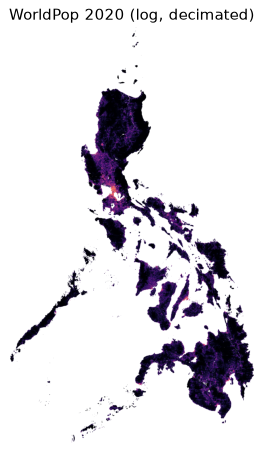

phl_children_under_five_2020_geotiff.zip (61200, 39600) total = 12.52 M


phl_elderly_60_plus_2020_geotiff.zip (61200, 39600) total = 7.50 M
[worldpop] WorldPop 2020 UN-adjusted total 109.6 M (PSA 2020 CPH: 109.0 M).


In [20]:
import rasterio
with rasterio.open(RAW / "worldpop/phl_ppp_2020_UNadj.tif") as r:
    a = r.read(1, out_shape=(r.height // 10, r.width // 10), masked=True)  # decimated preview
    full = sum(np.nansum(np.where(blk == r.nodata, 0, blk)) for _, w in r.block_windows(1) for blk in [r.read(1, window=w)])
    print("WorldPop 2020 UN-adj:", r.shape, r.res, f"total = {full/1e6:.1f} M")
plt.figure(figsize=(5, 6)); plt.imshow(np.log1p(a), cmap="magma"); plt.axis("off"); plt.title("WorldPop 2020 (log, decimated)"); plt.show()
for z in sorted((RAW / "meta_hrsl").glob("*.zip")):
    tif = [n for n in zipfile.ZipFile(z).namelist() if n.endswith(".tif")][0]
    with rasterio.open(f"zip://{z.as_posix()}!{tif}") as r:
        tot = sum(np.nansum(blk) for _, w in r.block_windows(1) for blk in [r.read(1, window=w)]); print(z.name, r.shape, f"total = {tot/1e6:.2f} M")
note("worldpop", f"WorldPop 2020 UN-adjusted total {full/1e6:.1f} M (PSA 2020 CPH: 109.0 M).")

## Summary: what the data say about the proposal

In [21]:
pd.DataFrame(FINDINGS, columns=["dataset", "finding"]).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,dataset,finding
0,dengue_hdx,"126 reporting units (provinces + 45 HUC/NCR cities), not 81 provinces; HUCs must be folded into their geographic province (or kept as separate nodes)."
1,dengue_hdx,"2016 deaths = 8127 (CFR 3.88%), implausibly high vs other years; treat deaths as unreliable."
2,dengue_hdx,"2020 cases = 91,041 vs 2019 441,902 (COVID reporting collapse), consistent with proposal using 2020 for access only. Data end 2021-01-10."
3,cchain,"Open city-week LEPTOSPIROSIS series exists (PIDSR via CCHAIN, 12 cities, 2008-2022). The proposal's 'no open subnational lepto series' is outdated; lepto can be a sub-national stretch goal without digitising DOH reports."
4,mendeley_parreno,"National weekly only, years [2019, 2020, 2021, 2022, 2023]; 2020 weeks present: 28/52. Does not cover 2016-2018, so it cannot cross-check Ompong (2018)."
5,opendengue,"V1.3 exists (May 2025). PHL = national weekly 2012-2023, region yearly to 2021, province monthly only 1994-2010; useful only as a national cross-check."
6,cod_ab,"COD-AB is current-boundary (88 ADM2: 4 NCR districts, Maguindanao del Norte/Sur split 2022, Special Geographic Area 2024). The 2016-2020 dengue units need a harmonised historical crosswalk. Name match: 126/126 units (BASILIG CITY = Bislig City, CARAGA). PSA PSGC 2Q 2026 must be downloaded manually (psa.gov.ph blocks scripts)."
7,ibtracs,"All 4 storms present; USA 34-kt radius available on 42%-85% of fixes, so the gale-radius buffer needs a fallback (e.g. TOKYO_R30 or a fixed radius)."
8,chirps,"CHIRPS v2.0 daily, 2016-01-01 to 2020-12-31 (1827 days, 0 missing), land only (sea is NaN); time axis is julian_day and must be converted."
9,imerg,"IMERG V07 daily via GEE: 1827 days 2016-01-01 to 2020-12-31, 0.1 deg; one GeoTIFF per month, band i = day i (no band names in the file)."
